<a href="https://colab.research.google.com/github/AhmadHusien-coder/Classification-Pipeline-for-Blood-Brain-Barrier-Penetration-BBBP-/blob/main/Part_1_BBBP_Data_Analysis_and_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1- Load Dataset**

In [ ]:
from datasets import load_dataset

ds = load_dataset("scikit-fingerprints/MoleculeNet_BBBP")

README.md:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

bbbp.csv:   0%|          | 0.00/111k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2039 [00:00<?, ? examples/s]

In [ ]:
df = ds['train'].to_pandas()

df

df.to_csv('dataSet.csv')

In [ ]:
df['SMILES'].isnull().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2039 entries, 0 to 2038
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   SMILES  2039 non-null   object
 1   label   2039 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 32.0+ KB


In [ ]:
df['label'].value_counts()

,count
label,
1,1560
0,479


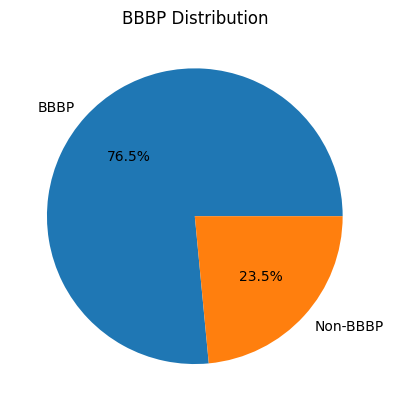

In [ ]:
import matplotlib.pyplot as plt

plt.pie(df['label'].value_counts(), autopct='%1.1f%%', labels=['BBBP', 'Non-BBBP'])
plt.title('BBBP Distribution')

plt.show()

# **2- Lipinski Properties Extraction**

*   **Molecular Weight:** Under 500 daltons (Da).
*   **Lipophilicity (Log P):** Not greater than 5 (a measure of fat solubility).
*   **Hydrogen Bond Donors:** No more than 5 (such as -OH and -NH groups).
*   **Hydrogen Bond Acceptors:** No more than 10 (such as N and O atoms).

In [ ]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 62.5 MB/s  0:00:00


In [ ]:
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors

In [ ]:
def lipinski(smiles, verbose=False):

  moldata = []
  for smile in smiles:
    mol = Chem.MolFromSmiles(smile)
    moldata.append(mol)

  basedata = np.arange(1, 1)

  i = 0
  for mol in moldata:
    mol_weight = Descriptors.MolWt(mol)
    mol_logp = Descriptors.MolLogP(mol)
    mol_hbd = Descriptors.NumHDonors(mol)
    mol_hba = Descriptors.NumHAcceptors(mol)

    row = np.array([mol_weight, mol_logp, mol_hbd, mol_hba])

    if (i == 0):
      basedata = row
    else:
      basedata = np.vstack([basedata, row])
    i = i + 1

  columnNames = ['MW', 'LogP', 'NumHDonors', 'NumHAcceptors']
  descriptors = pd.DataFrame(data=basedata, columns=columnNames)

  return descriptors

In [ ]:
df_descriptors = lipinski(df['SMILES'])
df_descriptors

[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:36] WARNING: not removing hydrogen atom without neighbors
[18:30:37] WARNING: not removing hydrogen atom without neighbors
[18:30:37] WARNING: not r

,MW,LogP,NumHDonors,NumHAcceptors
0,294.802,3.26700,2.0,3.0
1,360.325,4.63500,0.0,3.0
2,361.373,1.54400,1.0,5.0
3,290.407,2.57750,1.0,3.0
4,435.889,2.54872,2.0,6.0
...,...,...,...,...
2034,276.035,1.43140,2.0,4.0
2035,398.445,-3.25690,4.0,10.0
2036,322.368,4.79820,1.0,2.0
2037,382.460,4.51482,0.0,4.0


In [ ]:
df_descriptors.isnull().sum()

,0
MW,0
LogP,0
NumHDonors,0
NumHAcceptors,0


# **3- Data Visualization**

In [ ]:
df_descriptors['labels'] = df['label']

In [ ]:
df_descriptors.head()

,MW,LogP,NumHDonors,NumHAcceptors,labels
0,294.802,3.26700,2.0,3.0,1
1,360.325,4.63500,0.0,3.0,1
2,361.373,1.54400,1.0,5.0,1
3,290.407,2.57750,1.0,3.0,1
4,435.889,2.54872,2.0,6.0,1


In [ ]:
df_descriptors.to_csv('df_descriptors.csv', index=False)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

## **3-1- Scatter plot of MW of LogP**

We have a conclusion that the less the molecular weight get, the more it will penetrate BBB.

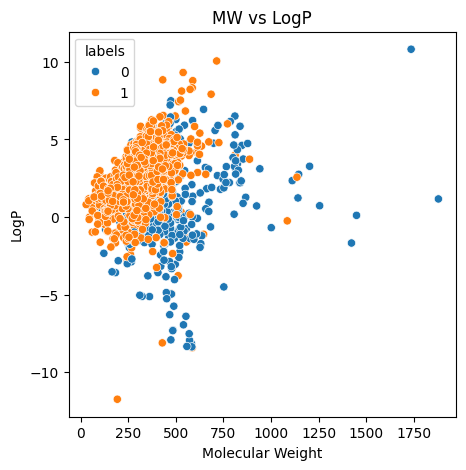

In [ ]:
plt.figure(figsize=(5, 5))

sns.scatterplot(x='MW', y='LogP', hue='labels', data=df_descriptors)
plt.title('MW vs LogP')

plt.xlabel('Molecular Weight')
plt.ylabel('LogP')

plt.savefig('plot_MW_vs_LogP.jpeg')

plt.show()

## **3-2- MW Box plot**

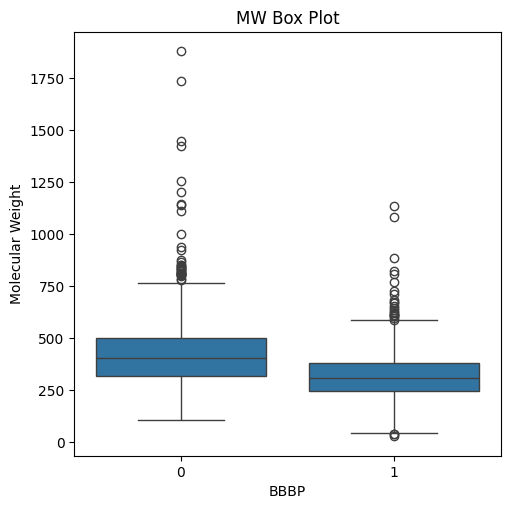

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='labels', y='MW', data=df_descriptors)
plt.title('MW Box Plot')

plt.xlabel('BBBP')
plt.ylabel('Molecular Weight')

plt.savefig('plot_MW_boxplot.jpeg')

plt.show()

## **3-3- LogP Box plot**

We have conclusion that the more LogP, more BBBP

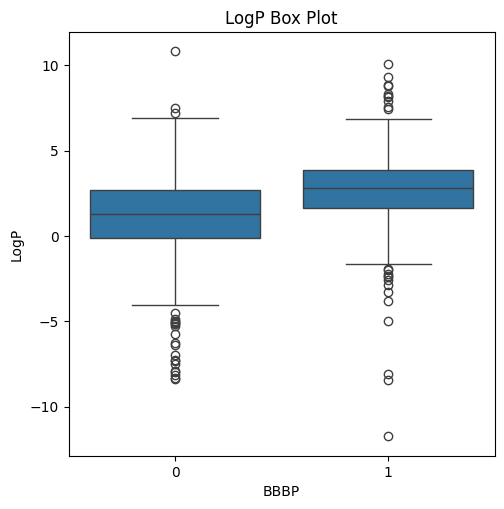

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='labels', y='LogP', data=df_descriptors)
plt.title('LogP Box Plot')

plt.xlabel('BBBP')
plt.ylabel('LogP')

plt.savefig('plot_LogP_boxplot.jpeg')

plt.show()

## **3-4- NumHDonors Box Plot**

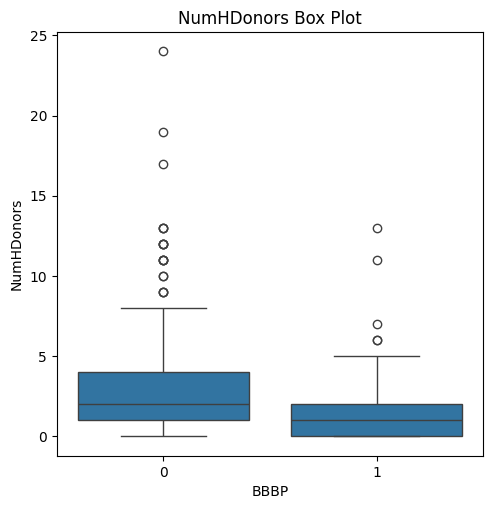

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='labels', y='NumHDonors', data=df_descriptors)
plt.title('NumHDonors Box Plot')

plt.xlabel('BBBP')
plt.ylabel('NumHDonors')

plt.savefig('plot_NumHDonors_boxplot.jpeg')

plt.show()

## **3-5- NumHAcceptors Box Plot**

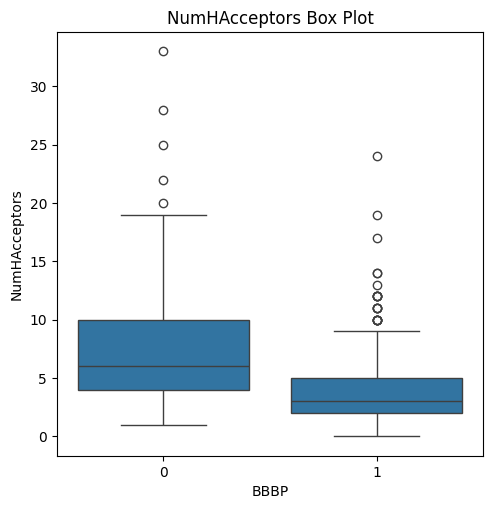

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x='labels', y='NumHAcceptors', data=df_descriptors)
plt.title('NumHAcceptors Box Plot')

plt.xlabel('BBBP')
plt.ylabel('NumHAcceptors')

plt.savefig('plot_NumHAcceptors_boxplo.jpeg')

plt.show()